# EDA and cleaning: Lubbock district crash export

This notebook is where I worked out what's actually in `district_crashes.csv` before building anything on top of it. It's focused on the columns I ended up using for the API (severity, contributing factors, time, location, road), not a profile of all 94 columns.

What I wanted to answer:

1. How is the file laid out, and what does one row represent?
2. Which columns are worth keeping, and why?
3. What's wrong with the data, and how should each problem be handled?

The cleaning logic itself lives in `pipeline/clean.py` so the API and this notebook use exactly the same code. Here I explore, then call those functions and check the results.

In [1]:
# Setup: make the pipeline and the API package importable from the notebook folder
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]

import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from pipeline import clean

RAW = ROOT / "data" / "raw" / "district_crashes.csv"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

## 1. Reading the file

The brief warned about non-data lines at the top. Here's what they look like:

In [2]:
# Print everything above the real header row
header_line = clean.find_header_line(RAW)
with open(RAW, encoding="utf-8-sig") as f:
    for i, line in enumerate(f):
        if i >= header_line:
            break
        if line.strip():
            print(line.strip()[:160])
print(f"\nReal header is on line {header_line + 1} of the file")

"All crash data available using this tool represents reportable data collected from Texas Peace Officer's Crash Reports (CR-3) received and processed by the Tex
"Query Result Counts:"
"Your query returned a total of 24,261 Crashes containing 48,043 Units and 67,906 Persons"
"Filters Applied to current Query:"
"Crash Year Is In  2020 or 2021 or 2022 or 2023 or 2024 or 2025 or 2026"
"TxDOT District Is Equal To LUBBOCK"
"Crash Severity Is In A - SUSPECTED SERIOUS INJURY or B - SUSPECTED MINOR INJURY or K - FATAL INJURY or C - POSSIBLE INJURY"

Real header is on line 12 of the file


The preamble is a disclaimer, TxDOT's own record counts, and the query filters. Two useful things come out of it:

- **TxDOT's counts** (24,261 crashes, 48,043 units, 67,906 persons). These give me something to reconcile against later.
- **The filters.** The export only includes K, A, B and C crashes, so there are **no property-damage-only crashes** in here. Every number in this project is "injury crashes", and I say that everywhere the numbers are shown.

Rather than hard-coding `skiprows=11`, `find_header_line` searches for the line starting with `"Crash ID"`. A future export with a slightly different preamble would still load. I also read every column as text (`dtype=str, keep_default_na=False`) so pandas doesn't quietly decide what counts as missing. CRIS has its own ideas about that (section 4).

In [3]:
# Load every column as text; missing values are handled explicitly later
raw = clean.read_raw(RAW)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")

67,906 rows x 94 columns


## 2. What does one row represent?

67,906 rows against 24,261 crashes in the preamble means a row isn't a crash.

In [4]:
# How many rows does each Crash ID have?
rows_per_crash = raw.groupby("Crash ID").size()
print(f"Unique crashes: {rows_per_crash.size:,}")
print(f"Rows per crash: mean {rows_per_crash.mean():.2f}, max {rows_per_crash.max()}")
rows_per_crash.value_counts().sort_index().head(10).rename("crashes").to_frame().T

Unique crashes: 24,261
Rows per crash: mean 2.80, max 58


,1,2,3,4,5,6,7,8,9,10
crashes,4136,8757,5495,2856,1550,746,365,168,90,35


In [5]:
# Which columns change between rows of the same crash? Those are the person/vehicle-level ones.
varies = raw.groupby("Crash ID").nunique().gt(1).any()
person_level = varies[varies].index.tolist()
crash_level = varies[~varies].index.tolist()
print(f"{len(crash_level)} crash-level columns, {len(person_level)} person/vehicle-level columns\n")
print("Person/vehicle-level:", ", ".join(person_level))

66 crash-level columns, 27 person/vehicle-level columns

Person/vehicle-level: Contributing Factor 1, Contributing Factor 2, Contributing Factor 3, Driver Alcohol Result, Driver Time of Death, Driver Zip Code, Vehicle Body Style, Vehicle CMV Flag, Vehicle Color, Vehicle Make, Vehicle Model Name, Vehicle Model Year, Vehicle Parked Flag, Person Age, Person Alcohol Result, Person Death Count, Person Ejected, Person Ethnicity, Person Gender, Person Helmet, Person Injury Severity, Person Time of Death, Person Total Injury Count, Person Type, Person Unknown Injury Count, Physical Location of An Occupant, Solicitation


**It's one row per person.** Every person involved in a crash (drivers, passengers, pedestrians) gets a row, and the other 66 crash-level columns are copied onto each one. One crash has 58 rows. That's probably a bus.

This is the most important finding in the whole EDA. If you run `value_counts()` on `Crash Severity` straight off the file, you count people rather than crashes and overstate everything by about 2.8x, and not evenly: bigger crashes get counted more times. So step one of cleaning is to collapse back to one row per `Crash ID`.

Before doing that I need to be sure the crash-level columns really are identical within a crash. Otherwise "keep the first row" would be an arbitrary choice. The check above shows they are. The pipeline repeats the check every time it runs and fails loudly if it ever stops being true.

I couldn't reconcile the 48,043 **units** (vehicles) because the export has no unit or vehicle ID column. Crashes and persons both reconcile exactly (section 6).

In [6]:
# One row per crash from here on, for exploring crash-level columns
crashes_raw = raw.drop_duplicates("Crash ID")
len(crashes_raw)

24261

## 3. Which columns are relevant?

A quick missingness check across the crash-level columns. CRIS writes missing values as text like `No Data`, so I count those as missing too.

In [7]:
# Share of crashes where each crash-level column is effectively empty
def is_missing(series):
    return series.map(clean.clean_text).isna()

missing = (
    crashes_raw[crash_level]
    .apply(is_missing)
    .mean()
    .sort_values(ascending=False)
    .rename("share_missing")
)
missing.to_frame().style.format("{:.0%}").bar(color="#f2b8a2", vmin=0, vmax=1)

,share_missing
Intersecting Street Number,100%
Feature Crossed by Bridge,100%
Intersecting Road Minimum Vertical Clearance,100%
Surface Type,100%
"Highway Lane Design for HOV, Railroads, and Toll Roads",100%
Intersecting Highway Alpha Suffix,100%
Highway Alpha Suffix,100%
Intersecting Highway System,83%
Intersecting Highway Number,83%
Street Number,51%


Here's how I sorted the columns. I'm deliberately keeping the set small. The brief asks for severity, factors and time patterns, and an analyst will want to filter by place and road type.

| Kept | Why |
|---|---|
| `Crash ID` | The grain of everything. Used to deduplicate. |
| `Crash Severity` | The K/A/B/C metric. Complete and clean. |
| `Contributing Factors` | Combined factor list for the crash (section 4.3 explains why this one and not the per-vehicle columns). |
| `Crash Date`, `Crash Time` | Yearly, monthly, hour-of-day and weekday trends. |
| `County`, `Road Class` | The obvious filters for a district-level dashboard. |
| `Latitude`, `Longitude` | Mapping. 3% missing. |
| `Street Name` | Lets me rank roads (corridors) by serious crashes. |
| `Crash Death Count`, `Crash Suspected Serious Injury Count`, `Crash Total Injury Count` | People killed or hurt, not just crash counts. |
| `Speed Limit`, `Weather Condition`, `First Harmful Event`, `Intersection Related`, `Rural Flag` | Cheap context that's useful for filtering later. |
| `Person Type` (person-level) | Rolled up to "did this crash involve a pedestrian / cyclist / motorcyclist". Vulnerable road users are a standard safety cut. |

**Dropped:**

- **Always empty:** `Feature Crossed by Bridge`, `Surface Type`, `Intersecting Road Minimum Vertical Clearance`, `Intersecting Street Number`, `Highway Lane Design for HOV...`.
- **Road inventory** (traffic volume, lane counts, shoulders, roadbed width and so on): 44% missing. That's interesting in itself, and section 4.6 looks at it.
- **Duplicate information:** `Crash Year` and `Hour of Day` are derived from the date and time. I check they agree, then derive them myself. `Fatal Crash Flag` is just severity K.
- **Personal details** (age, gender, ethnicity, driver ZIP, alcohol results, time of death): not needed for any of the metrics. They also shouldn't be served from a public API, so they never leave the pipeline.
- **Vehicle details** (make, model, colour): out of scope for the time available.

## 4. Data quality issues

### 4.1 Many ways of saying "missing"

In [8]:
# Count each missing-value spelling across all columns
tokens = ["", "No Data", "NO DATA", "N/A", "NOT REPORTED", "UNKNOWN", "-1"]
found = {t if t else "(empty string)": int((raw == t).sum().sum()) for t in tokens}
unknown_codes = int(raw.apply(lambda s: s.str.match(r"^9[79] - (UNKNOWN|NOT APPLICABLE)$")).sum().sum())
found["99 - UNKNOWN / 97 - NOT APPLICABLE"] = unknown_codes
pd.Series(found, name="cells").to_frame()

,cells
(empty string),46467
No Data,1361742
NO DATA,102065
N/A,27780
NOT REPORTED,1723
UNKNOWN,664
-1,80682
99 - UNKNOWN / 97 - NOT APPLICABLE,74440


Missing data shows up as empty strings, `No Data`, `NO DATA`, `N/A`, `NOT REPORTED`, `-1` and coded unknowns like `99 - UNKNOWN`. `clean_text()` upper-cases and trims every value, then maps all of these to a real null in one place, so the rest of the code never has to remember them.

### 4.2 Inconsistent casing and formats

In [9]:
# The same yes/no idea is written differently in different columns
flag_columns = ["Active School Zone Flag", "At Intersection Flag", "Construction Zone Flag",
                "Rural Flag", "Fatal Crash Flag", "Toll Road Flag", "TxDOT Reportable Flag"]
pd.DataFrame({col: [", ".join(sorted(crashes_raw[col].unique()))] for col in flag_columns}, index=["values"]).T

,values
Active School Zone Flag,"NO, YES"
At Intersection Flag,"false, true"
Construction Zone Flag,"No, Yes"
Rural Flag,"No, Yes"
Fatal Crash Flag,"0, 1"
Toll Road Flag,"NO, YES"
TxDOT Reportable Flag,"No, Yes"


Flags come as `YES/NO`, `Yes/No`, `true/false` and `0/1` depending on the column. Text is upper-case in most columns, but not all of them (`No Data` vs `NO DATA`). Everything I keep goes through the same normaliser: upper-case for comparison and `yes_no()` for flags. Display names like counties are then title-cased once at the end (`LUBBOCK` becomes `Lubbock`, while `US & STATE HIGHWAYS` becomes `US & State Highways`, not `Us & State Highways`).

`Crash Time` is stored as text like `0140`, so it has to be parsed rather than treated as a number. All 24,261 values parse to a valid hour and agree with the `Hour of Day` column.

In [10]:
# Check: Crash Year matches the date, and Hour of Day matches Crash Time
year_ok = (crashes_raw["Crash Year"] == crashes_raw["Crash Date"].str[:4]).all()
hour_ok = (crashes_raw["Crash Time"].map(clean.parse_hour) == crashes_raw["Hour of Day"].str[:2].astype(int)).all()
print("Year matches date:", year_ok)
print("Hour matches time:", hour_ok)

Year matches date: True
Hour matches time: True


### 4.3 Contributing factors: the trickiest column

The brief asks for "top 5 contributing factors", which sounds like a one-liner. It isn't:

In [11]:
# How factors are written in the combined crash-level field
factors_raw = crashes_raw["Contributing Factors"]
multi = factors_raw.str.contains(";")
print(f"Crashes with more than one factor: {multi.sum():,}")
print(f"  ...separated by ';'  (no space): {(multi & ~factors_raw.str.contains('; ')).sum():,}")
print(f"  ...separated by '; ' (with space): {factors_raw.str.contains('; ').sum():,}")
print(f"Crashes with factor 'NONE': {(factors_raw.str.strip() == 'NONE').sum():,}")
print(f"Crashes citing 'OTHER (EXPLAIN IN NARRATIVE)': {factors_raw.str.contains('OTHER \\(EXPLAIN', regex=True).sum():,}")
factors_raw[multi].head(5).to_frame()

Crashes with more than one factor: 6,128
  ...separated by ';'  (no space): 2,856
  ...separated by '; ' (with space): 3,272
Crashes with factor 'NONE': 104
Crashes citing 'OTHER (EXPLAIN IN NARRATIVE)': 1,604


,Contributing Factors
10,FAILED TO CONTROL SPEED;CELL/MOBILE DEVICE USE - TEXTING
15,DRIVER INATTENTION;FAILED TO YIELD RIGHT OF WAY - STOP SIGN
60,FAILED TO CONTROL SPEED; UNDER INFLUENCE - ALCOHOL
75,FAILED TO CONTROL SPEED; UNDER INFLUENCE - ALCOHOL
81,FAILED TO CONTROL SPEED; UNDER INFLUENCE - ALCOHOL


Issues and decisions:

- **Multiple factors in one cell, with two separator styles.** Splitting on `;` without trimming would turn `" UNSAFE SPEED"` and `"UNSAFE SPEED"` into two different factors. `parse_factors()` splits, trims, upper-cases and de-duplicates within the crash. There are no in-crash duplicates in this export, but it costs nothing to guard against them.
- **What does "frequency" mean?** I count **crashes that cite each factor**, so a crash with two factors contributes once to each. The share is out of *all* crashes in the filter, so it reads naturally: "23% of fatal crashes involved failing to drive in a single lane".
- **`NONE`** means no factor was recorded. It's dropped from the factor list (104 crashes), but those crashes still count in the denominator.
- **`OTHER (EXPLAIN IN NARRATIVE)`** means the reason is in the officer's free-text narrative, which isn't in this export. It's left out of the ranking by default, because "other" isn't something an analyst can act on. The API still reports how many crashes cited it, and `include_unspecified=true` puts it back.

**Combined field vs per-vehicle columns.** The file also has `Contributing Factor 1/2/3` on each row, attributed to individual vehicles. I compared the two:

In [12]:
# Compare the combined field with the union of the per-vehicle factor columns, crash by crash
factor_cols = ["Contributing Factor 1", "Contributing Factor 2", "Contributing Factor 3"]
strip_code = lambda v: re.sub(r"^\d+ - ", "", v).strip()

long = raw.melt(id_vars="Crash ID", value_vars=factor_cols)
long = long[long["value"] != "No Data"]
per_vehicle = long.assign(value=long["value"].map(strip_code)).groupby("Crash ID")["value"].agg(set)
combined = crashes_raw.set_index("Crash ID")["Contributing Factors"].map(lambda v: set(clean.parse_factors(v)))
per_vehicle = per_vehicle.reindex(combined.index).map(lambda v: v if isinstance(v, set) else set())

only_combined, only_vehicle = Counter(), Counter()
for cid in combined.index:
    only_combined.update(combined[cid] - per_vehicle[cid])
    only_vehicle.update(per_vehicle[cid] - combined[cid])

print(f"Crashes where the two agree: {(combined == per_vehicle).sum():,} of {len(combined):,}")
print("\nOnly in the combined field:", only_combined.most_common(5))
print("\nOnly in the per-vehicle columns:", only_vehicle.most_common(3))

Crashes where the two agree: 21,010 of 24,261

Only in the combined field: [('UNDER INFLUENCE - ALCOHOL', 1255), ('DRIVER INATTENTION', 407), ('HAD BEEN DRINKING', 158), ('OTHER (EXPLAIN IN NARRATIVE)', 143), ('FATIGUED OR ASLEEP', 135)]

Only in the per-vehicle columns: [('INTOXICATED - ALCOHOL', 1109), ('INTOXICATED - DRUG', 75), ('FAILED TO HEED WARNING SIGN OR TRAFFIC CONTROL DEVICE', 32)]


The combined field is the better source:

- It contains **everything** the per-vehicle columns have, plus extra factors in a couple of thousand crashes, mostly alcohol, inattention and fatigue.
- The per-vehicle columns are blank on about half the rows, including many drivers.
- The one real "disagreement" is a **naming difference for the same code**. Code 67 is `INTOXICATED - ALCOHOL` in the per-vehicle columns and `UNDER INFLUENCE - ALCOHOL` in the combined field. If I ever combined the two sources I'd map them to one label. Since I only use the combined field, it doesn't affect the numbers, but it's the kind of thing that silently splits one factor into two.

### 4.4 Severity, deaths and the fatal flag agree

In [13]:
# Every K crash should have the fatal flag set and at least one death, and nothing else should
sev = crashes_raw["Crash Severity"].str[0]
deaths = crashes_raw["Crash Death Count"].astype(int)
print("Severity values:", sorted(crashes_raw["Crash Severity"].unique()))
print("K <-> Fatal Crash Flag mismatches:", ((sev == "K") != (crashes_raw["Fatal Crash Flag"] == "1")).sum())
print("K crashes with zero deaths:", ((sev == "K") & (deaths == 0)).sum())
print("Non-K crashes with deaths:", ((sev != "K") & (deaths > 0)).sum())

Severity values: ['A - SUSPECTED SERIOUS INJURY', 'B - SUSPECTED MINOR INJURY', 'C - POSSIBLE INJURY', 'K - FATAL INJURY']
K <-> Fatal Crash Flag mismatches: 0
K crashes with zero deaths: 0
Non-K crashes with deaths: 0


Severity is clean: four values, no blanks, and it agrees with the fatal flag and the death counts. I keep just the letter (`K`, `A`, `B`, `C`). If a row ever came through without a valid severity, the pipeline drops it with a warning rather than guessing.

### 4.5 Location

In [14]:
# Missing and out-of-range coordinates
lat = crashes_raw["Latitude"].map(lambda v: clean.to_coordinate(v, clean.TX_LAT))
lon = crashes_raw["Longitude"].map(lambda v: clean.to_coordinate(v, clean.TX_LON))
print(f"Missing coordinates: {lat.isna().sum():,} crashes ({lat.isna().mean():.1%})")
print(f"Latitude range:  {lat.min():.3f} to {lat.max():.3f}")
print(f"Longitude range: {lon.min():.3f} to {lon.max():.3f}")

Missing coordinates: 849 crashes (3.5%)
Latitude range:  32.525 to 34.747
Longitude range: -103.065 to -101.043


849 crashes (3.5%) say `No Data` for both coordinates. Everything else falls inside the district, so there are no flipped signs or zero coordinates in this export. The pipeline still bounds-checks against a Texas box and drops both coordinates if either one fails, because half a coordinate is useless on a map. Crashes without coordinates **stay in every count**. They just can't go on the map, and the dashboard says so.

### 4.6 The road inventory gap isn't random

In [15]:
# Traffic-volume (and the other road-inventory columns) missing, by road class
inventory_missing = crashes_raw["Adjusted Average Daily Traffic Amount"].eq("No Data")
pd.crosstab(crashes_raw["Road Class"], inventory_missing, normalize="index").rename(
    columns={False: "has inventory", True: "missing"}
).style.format("{:.0%}")

Adjusted Average Daily Traffic Amount,has inventory,missing
Road Class,,
CITY STREET,19%,81%
COUNTY ROAD,5%,95%
FARM TO MARKET,96%,4%
INTERSTATE,97%,3%
NON TRAFFICWAY,0%,100%
OTHER ROADS,5%,95%
US & STATE HIGHWAYS,95%,5%


Traffic volume, lane counts, shoulder widths and the other inventory fields are all missing for the same 10,727 crashes. That's 81% of city-street crashes, every non-trafficway crash (parking lots and the like), but only about 5% of US and state highway crashes. These fields come from TxDOT's road inventory, which mostly covers the state-maintained system.

So the gap is **structural, not random**. Filling it with averages would be wrong, and any per-traffic-volume crash *rate* would only be valid for highways. I left these columns out. A crash-rate endpoint for state highways would be a good next step.

### 4.7 Other things worth knowing

In [16]:
# Speed limit -1, non-trafficway crashes, and incomplete investigations
speed = crashes_raw["Speed Limit"]
print(f"Speed limit = -1 (unknown): {(speed == '-1').sum()} crashes")
print("\nRoad class vs TxDOT Reportable flag:")
print(pd.crosstab(crashes_raw["Road Class"] == "NON TRAFFICWAY", crashes_raw["TxDOT Reportable Flag"]))
print("\nShare of crashes with investigation not complete, by year:")
print((crashes_raw["Investigation Complete"] == "NO").groupby(crashes_raw["Crash Year"]).mean().round(3).to_string())

Speed limit = -1 (unknown): 191 crashes

Road class vs TxDOT Reportable flag:
TxDOT Reportable Flag   No    Yes
Road Class                       
False                    0  23479
True                   782      0

Share of crashes with investigation not complete, by year:
Crash Year
2020    0.067
2021    0.073
2022    0.065
2023    0.065
2024    0.063
2025    0.068
2026    0.072


- **Speed limit `-1`** (191 crashes) means unknown. It's treated as missing, not as a number.
- **782 "non-trafficway" crashes** (parking lots, private property) are exactly the ones flagged as *not* TxDOT-reportable. I keep them because the export includes them and they're real injury crashes, but `road_class` lets anyone filter them out.
- **About 7% of crashes are marked "investigation not complete"** in every year, not just recent ones, so it doesn't look like a recency effect. I don't filter on it.

### 4.8 The last year is partial

In [17]:
# 2026 crashes by month: the export stops on Oct 20
crash_dates = pd.to_datetime(crashes_raw["Crash Date"])
print("Latest crash date:", crash_dates.max().date())
crash_dates[crash_dates.dt.year == 2026].dt.month.value_counts().sort_index().rename("crashes").to_frame().T

Latest crash date: 2026-10-20


Crash Date,1,2,3,4,5,6,7,8,9,10
crashes,255,229,280,265,278,270,260,331,322,164


The data runs to **20 October 2026**. A plain yearly chart makes 2026 look like a sharp drop, but it's just ten months of data. I didn't annualise it, because crashes are seasonal and recent reports are still trickling in. Instead:

- the API marks the current year/month as `complete: false`, and
- `/api/trends?same_period=true` compares **1 Jan – 20 Oct in every year**, which is the fair year-over-year comparison.

Even that comparison may slightly undercount the last few weeks of 2026 while late reports arrive, and the API notes say so.

## 5. Cleaning decisions

| Issue | Decision | Why |
|---|---|---|
| Preamble above the header | Find the `Crash ID` line instead of a fixed `skiprows` | Survives changes to the preamble |
| One row per person | Collapse to one row per `Crash ID`, after checking crash-level columns are identical within a crash | Every metric is about crashes |
| Many missing-value spellings | Map all of them to null in `clean_text()` | One rule, applied everywhere |
| Inconsistent casing / flag formats | Upper-case for comparison, title-case for display, `yes_no()` for flags | Filters and counts don't split on case |
| Multi-factor cells, mixed `;` / `; ` | Split, trim, de-duplicate per crash | Otherwise one factor counts as two |
| `NONE` factor | Drop from the list, keep the crash | It means no factor recorded |
| `OTHER (EXPLAIN IN NARRATIVE)` | Excluded from the ranking by default, reported separately | Not actionable without the narrative |
| Combined vs per-vehicle factor columns | Use the combined field | More complete; avoids the alcohol label mismatch |
| `No Data` / out-of-range coordinates | Null both, keep the crash | Still counts, just not mappable |
| Speed limit `-1` | Null | Means unknown |
| Road inventory 44% missing (structurally) | Not used | Can't be filled honestly |
| Road names like `SL0289` | Turned into `Loop 289`, `I-27`, `US 84` | Readable for people who know the roads |
| Person details (age, ZIP, ethnicity...) | Never leave the pipeline | Not needed, and not appropriate for a public API |
| 2026 is partial | Flag it, and offer a same-period comparison | Don't annualise seasonal, still-arriving data |

## 6. Run the pipeline and reconcile

In [18]:
# Run the real cleaning pipeline and compare our counts with TxDOT's preamble
out = ROOT / "src" / "crash_api" / "data" / "crashes.json.gz"
meta = clean.run(RAW, out)

 crashes: ours=24,261  txdot=24,261  ok
 persons: ours=67,906  txdot=67,906  ok


wrote 24,261 crashes to src/crash_api/data/crashes.json.gz


In [19]:
# Load the cleaned output exactly as the API does
from crash_api import metrics
from crash_api.data import CrashStore

store = CrashStore.from_file(out)
crashes = store.crashes
df = pd.DataFrame(crashes)
df.head()

,crash_id,date,year,month,hour,weekday,county,severity,factors,lat,...,weather,first_harmful_event,deaths,serious_injuries,total_injuries,rural,intersection,pedestrian,cyclist,motorcyclist
0,17490845,2020-01-01,2020,1,1,Wednesday,Lubbock,C,[FAILED TO CONTROL SPEED],33.534378,...,CLEAR,MOTOR VEHICLE IN TRANSPORT,0,0,1,False,INTERSECTION RELATED,False,False,False
1,17490922,2020-01-01,2020,1,9,Wednesday,Lubbock,K,[BACKED WITHOUT SAFETY],33.581722,...,CLOUDY,PEDESTRIAN,1,0,0,False,DRIVEWAY ACCESS,True,False,False
2,17491806,2020-01-01,2020,1,0,Wednesday,Lubbock,B,[FAILED TO PASS TO LEFT SAFELY],33.571416,...,CLEAR,PARKED CAR,0,0,1,False,NON INTERSECTION,True,False,False
3,17491810,2020-01-01,2020,1,1,Wednesday,Lubbock,B,"[UNDER INFLUENCE - ALCOHOL, UNSAFE SPEED]",33.525279,...,CLEAR,FIXED OBJECT,0,0,1,False,NON INTERSECTION,False,False,False
4,17491908,2020-01-01,2020,1,18,Wednesday,Lubbock,B,"[FAILED TO DRIVE IN SINGLE LANE, ILL (EXPLAIN IN NARRATIVE)]",33.523604,...,CLEAR,FIXED OBJECT,0,0,5,False,NON INTERSECTION,False,False,False


Crashes and persons both match TxDOT's numbers exactly, so nothing was lost or double-counted.

## 7. First look at the results

These are the three required metrics, computed by the same functions the API calls.

In [20]:
# 1. Crashes by severity
pd.DataFrame(metrics.severity_counts(crashes)).set_index("code").style.format({"share": "{:.1%}", "crashes": "{:,}"})

,label,crashes,share
code,,,
K,Fatal,624,2.6%
A,Suspected serious injury,"1,546",6.4%
B,Suspected minor injury,"7,224",29.8%
C,Possible injury,"14,867",61.3%


In [21]:
# 2. Top 5 contributing factors, all crashes and fatal + serious (KA) only
ka = [c for c in crashes if c["severity"] in "KA"]
top_all = pd.DataFrame(metrics.top_factors(crashes, n=5)["factors"]).set_index("rank")
top_ka = pd.DataFrame(metrics.top_factors(ka, n=5)["factors"]).set_index("rank")
pd.concat({"All injury crashes": top_all[["factor", "share_of_crashes"]],
           "Fatal + serious (KA)": top_ka[["factor", "share_of_crashes"]]}, axis=1).style.format(
    {("All injury crashes", "share_of_crashes"): "{:.1%}", ("Fatal + serious (KA)", "share_of_crashes"): "{:.1%}"})

"Failed to control speed" dominates injury crashes overall, but the **fatal and serious crashes look different**. Failing to stay in a single lane, unsafe speed and alcohol move to the top. That's what lane departures on rural highways look like. It's also why a `severity` filter matters more than any other on these endpoints: the top-5 changes depending on which crashes you're asking about.

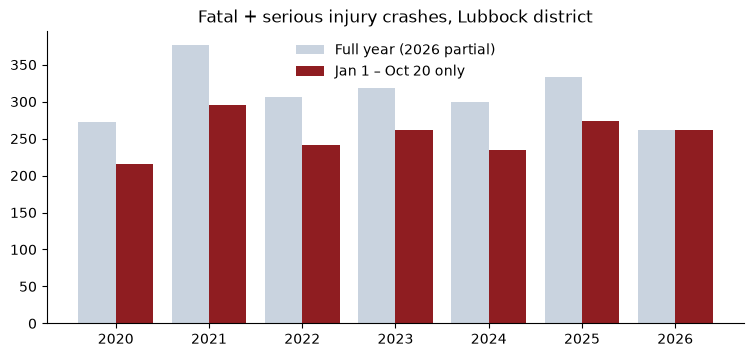

period,2020,2021,2022,2023,2024,2025,2026
full year,273,377,306,319,300,333,262
Jan 1 - Oct 20,216,296,241,262,235,274,262


In [22]:
# 3. Time patterns: fatal + serious crashes by year, full year vs same Jan 1 - Oct 20 window
full = pd.DataFrame(metrics.trend(ka, by="year", latest_date=store.latest_date)).set_index("period")["KA"]
same = pd.DataFrame(metrics.trend(metrics.same_period_only(ka, store.latest_date), by="year")).set_index("period")["KA"]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(full))
ax.bar([i - 0.2 for i in x], full.values, width=0.4, label="Full year (2026 partial)", color="#c9d3df")
ax.bar([i + 0.2 for i in x], same.values, width=0.4, label="Jan 1 – Oct 20 only", color="#8f1d21")
ax.set_xticks(list(x), full.index)
ax.set_title("Fatal + serious injury crashes, Lubbock district")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
pd.DataFrame({"full year": full, "Jan 1 - Oct 20": same}).T

On a like-for-like basis, 2026 (262 KA crashes so far) is running a little below 2025 (274) and well below the 2021 peak (296). The full-year bars would have made 2026 look like a 20% drop, which is the mistake the same-period view avoids.

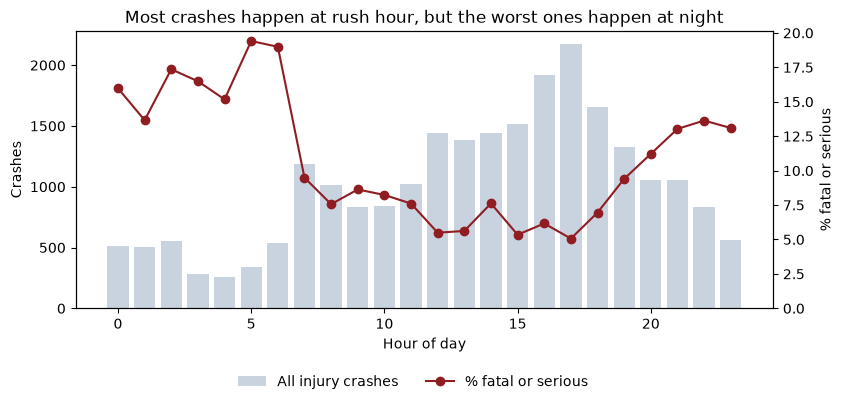

In [23]:
# Time of day: share of crashes in each hour that were fatal or serious
hours = pd.DataFrame(metrics.trend(crashes, by="hour")).set_index("period")
hours["ka_share"] = hours["KA"] / hours["total"]

fig, ax1 = plt.subplots(figsize=(9, 3.6))
ax1.bar(hours.index, hours["total"], color="#c9d3df", label="All injury crashes")
ax2 = ax1.twinx()
ax2.plot(hours.index, hours["ka_share"] * 100, color="#8f1d21", marker="o", label="% fatal or serious")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Crashes")
ax2.set_ylabel("% fatal or serious")
ax1.set_title("Most crashes happen at rush hour, but the worst ones happen at night")
ax2.set_ylim(0, None)
fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.show()

Crash volume follows traffic and peaks around 5pm. But only about 1 in 20 of those rush-hour crashes is fatal or serious, compared with roughly 1 in 6 between midnight and 6am. Fewer crashes happen at night, but they're far more likely to kill or seriously hurt someone (speed, alcohol and darkness all play a part). That's why the `by=hour` trend returns K/A/B/C counts and not just totals.

In [24]:
# Where: roads with the most fatal + serious crashes, vs most crashes overall
pd.concat({
    "Most KA crashes": pd.DataFrame(metrics.top_roads(ka, n=8)).set_index("road")["crashes"].reset_index(),
    "Most crashes overall": pd.DataFrame(metrics.top_roads(crashes, n=8)).set_index("road")["crashes"].reset_index(),
}, axis=1)

Most KA crashes         Most crashes overall        
             road crashes                 road crashes
0           US 84     217             Loop 289    2082
1           US 62     198                US 62    1759
2            I-27     124                US 84    1634
3           US 87      88                 I-27    1196
4        Loop 289      86               SH 114     952
5          SH 114      71             SLIDE RD     788
6           US 70      69                US 82     760
7          US 385      60              82ND ST     686

Loop 289 has the most injury crashes overall, but **US 84 and US 62 have the most fatal and serious ones**. Higher speeds on the US highways out of Lubbock turn crashes into KA crashes more often than the congested loop does. For someone deciding where to spend safety money, the KA ranking is the more useful one, and it's what the dashboard shows.

## 8. What I'd look at next

- **Crash rates, not just counts**, using traffic volume for state highways (the road inventory columns cover most of them).
- **Mapping alcohol labels** across the combined and per-vehicle factor fields if the per-vehicle attribution is ever needed.
- **Hot spots** by snapping crashes to road segments, rather than just ranking road names.
- **Reporting lag:** pull the same export again in a few months to see how much the last few weeks of 2026 grow.